In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
index = np.array([0,1,2,3,4,5,6,7,8,9])

signal = np.array([
    -1,
    1,
    2,
    1,
    0,
    -1,
    1,
    2,
    1,
    -2
])

print(index)
print(signal)

[0 1 2 3 4 5 6 7 8 9]
[-1  1  2  1  0 -1  1  2  1 -2]


# Zero Crossing Analysis

This notebook contains the solutions for the REHAB Python Series03 assignment.

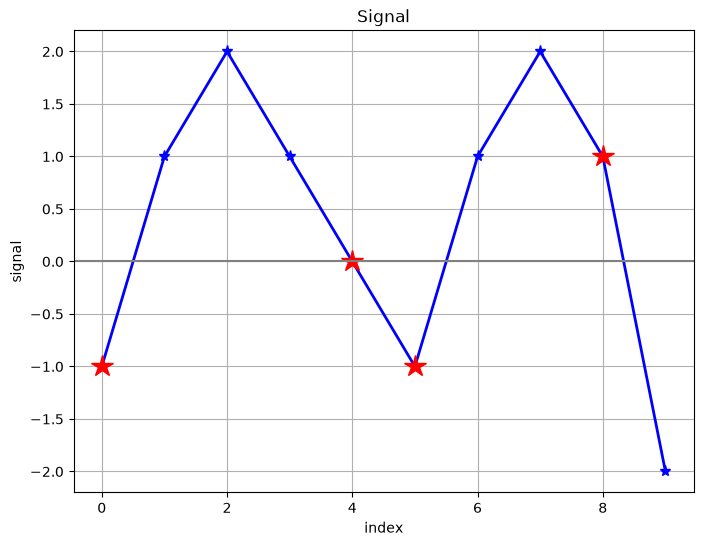

In [1]:
import matplotlib.pyplot as plt

# Données
index = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
signal = [-1, 1, 2, 1, 0, -1, 1, 2, 1, -2]

# Courbe principale
plt.figure(figsize=(8, 6))
plt.plot(index, signal, 'b-*', linewidth=2, markersize=8)

# Points rouges
x_red = [0, 4, 5, 8]
y_red = [-1, 0, -1, 1]
plt.plot(x_red, y_red, 'r*', markersize=16)

# Axe horizontal y=0
plt.axhline(0, color='gray', linewidth=1.5)

# Grille
plt.grid(True)

# Labels
plt.xlabel("index")
plt.ylabel("signal")

# Titre optionnel
plt.title("Signal")

plt.show()

In [3]:
def find_zero_crossings_no_zeros(signs):
    """
    Find positive and negative zero crossings in a sign array
    that does not contain any zeros.

    Parameters
    ----------
    signs : np.ndarray
        Array containing only -1 and +1 values.

    Returns
    -------
    tuple
        i_cross_pos : indices of negative-to-positive crossings
        i_cross_neg : indices of positive-to-negative crossings
    """

    diff = np.diff(signs)

    i_cross_pos = np.where(diff > 0)[0]
    i_cross_neg = np.where(diff < 0)[0]

    return i_cross_pos, i_cross_neg

In [4]:
def propagate_signs_over_zeros(signs):
    """
    Replace zero values by propagating the nearest previous
    non-zero sign.

    Parameters
    ----------
    signs : np.ndarray
        Array containing -1, 0 and +1.

    Returns
    -------
    np.ndarray
        Sign array without zeros.
    """

    signs_no_zeros = signs.copy()

    mask = signs_no_zeros != 0

    idx = np.where(
        mask,
        np.arange(len(signs_no_zeros)),
        0
    )

    idx = np.maximum.accumulate(idx)

    signs_no_zeros = signs_no_zeros[idx]

    if signs_no_zeros[0] == 0:

        i_first_nonzero = np.where(signs != 0)[0]

        if len(i_first_nonzero) > 0:

            signs_no_zeros[:i_first_nonzero[0]] = \
                signs[i_first_nonzero[0]]

    return signs_no_zeros

In [5]:
def find_zero_crossings(s):
    """
    Detect positive and negative zero crossings in a signal.

    Parameters
    ----------
    s : np.ndarray
        Input 1D signal.

    Returns
    -------
    tuple
        i_cross_pos : negative-to-positive crossings
        i_cross_neg : positive-to-negative crossings
    """

    s = np.asarray(s)

    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # Convert the signal into signs (-1,0,+1)
    signs = np.sign(s).astype(int)

    # Identify zero values
    i_zeros = np.where(signs == 0)[0]

    # Remove zeros before detecting crossings
    if i_zeros.size > 0:
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs

    return find_zero_crossings_no_zeros(signs_no_zeros)

In [6]:
i_pos, i_neg = find_zero_crossings(signal)

print("Positive crossings:", i_pos)
print("Negative crossings:", i_neg)

Positive crossings: [0 5]
Negative crossings: [4 8]


In [7]:
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings."""

    s = np.array([-1, 1, -1, 1, -1])

    i_pos, i_neg = find_zero_crossings(s)

    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))

    s = np.array([-1, 0, 0, 1, 0, -1])

    i_pos, i_neg = find_zero_crossings(s)

    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    print("All tests passed.")

In [8]:
test_find_zero_crossings()

All tests passed.


In [9]:
# Signal entièrement positif
s = np.array([1, 2, 3, 4])

i_pos, i_neg = find_zero_crossings(s)

assert len(i_pos) == 0
assert len(i_neg) == 0

# Signal entièrement négatif
s = np.array([-1, -2, -3, -4])

i_pos, i_neg = find_zero_crossings(s)

assert len(i_pos) == 0
assert len(i_neg) == 0

# Que des zéros
s = np.array([0, 0, 0, 0])

i_pos, i_neg = find_zero_crossings(s)

assert len(i_pos) == 0
assert len(i_neg) == 0

print("Additional tests passed.")

Additional tests passed.


In [10]:
def find_local_maxima(signal):
    """
    Find indices of local maxima.
    """

    return np.where(
        (signal[1:-1] > signal[:-2]) &
        (signal[1:-1] > signal[2:])
    )[0] + 1

In [11]:
def find_local_minima(signal):
    """
    Find indices of local minima.
    """

    return np.where(
        (signal[1:-1] < signal[:-2]) &
        (signal[1:-1] < signal[2:])
    )[0] + 1

In [12]:
i_max = find_local_maxima(signal)
i_min = find_local_minima(signal)

print("Maxima :", i_max)
print("Minima :", i_min)

Maxima : [2 7]
Minima : [5]


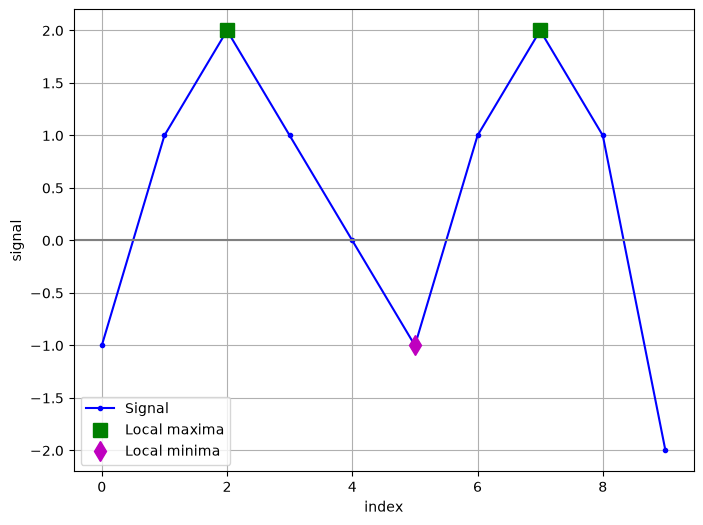

In [13]:
plt.figure(figsize=(8, 6))

plt.plot(index, signal, 'b.-', label='Signal')

i_max = find_local_maxima(signal)
i_min = find_local_minima(signal)

plt.plot(
    index[i_max],
    signal[i_max],
    'sg',
    markersize=10,
    label='Local maxima'
)

plt.plot(
    index[i_min],
    signal[i_min],
    'dm',
    markersize=10,
    label='Local minima'
)

plt.axhline(y=0, color='gray')

plt.grid(True)

plt.xlabel("index")
plt.ylabel("signal")

plt.legend()

plt.show()

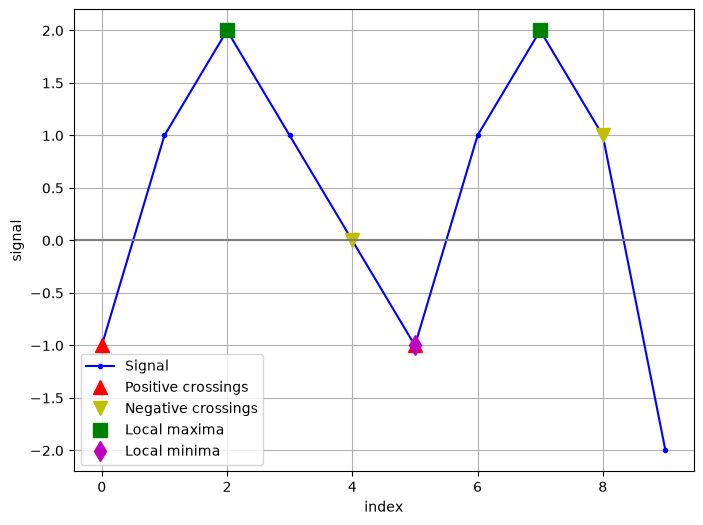

In [14]:
i_pos, i_neg = find_zero_crossings(signal)

plt.figure(figsize=(8, 6))

plt.plot(index, signal, 'b.-', label='Signal')

plt.plot(
    index[i_pos],
    signal[i_pos],
    '^r',
    markersize=10,
    label='Positive crossings'
)

plt.plot(
    index[i_neg],
    signal[i_neg],
    'vy',
    markersize=10,
    label='Negative crossings'
)

plt.plot(
    index[i_max],
    signal[i_max],
    'sg',
    markersize=10,
    label='Local maxima'
)

plt.plot(
    index[i_min],
    signal[i_min],
    'dm',
    markersize=10,
    label='Local minima'
)

plt.axhline(y=0, color='gray')

plt.grid(True)

plt.xlabel("index")
plt.ylabel("signal")

plt.legend()

plt.show()

# Role of unit tests

Unit tests verify that the find_zero_crossings() function behaves correctly under different conditions.

The tests ensure that:

positive crossings are correctly detected;
negative crossings are correctly detected;
signals containing zeros are correctly handled;
signals without crossings return empty arrays;
edge cases do not break the function.

Unit testing helps detect errors and ensures that future modifications do not break the expected behaviour.